# Movie Recommendation System (MovieLens)

**Topic 1: Recommendation Systems | CRISP-DM**

## Project overview

This project presents an offline movie recommendation prototype that generates **five movie recommendations a user has not rated previously**. Recommendations are informed by the user's existing movie ratings and the characteristics of movies in the catalogue.

The primary approach is **item-based collaborative filtering**, which identifies movies with similar user-rating patterns. **Content-based filtering** complements this approach by comparing movie genres, providing an additional signal when rating history is limited. These methods are combined in a **hybrid recommendation model** and made available through a Python function named `recommend()`.

### Project workflow: CRISP-DM
1. **Business understanding** – define the recommendation problem and evaluation criteria.
2. **Data understanding** – examine the MovieLens ratings and movie metadata.
3. **Data preparation** – split the ratings, estimate user and item biases, calculate residuals, and prepare genre features.
4. **Modelling** – develop baseline, collaborative, content-based and hybrid approaches.
5. **Evaluation** – compare rating-prediction accuracy and top-five recommendation relevance.
6. **Deployment** – implement a function that accepts a user's ratings and returns five recommendations.

**Project scope:** The result is an offline prototype. It demonstrates a recommendation workflow using historical data; it is not connected to a live streaming platform or real-time user activity.

## 1. Business Understanding

### The business problem

A movie-streaming platform needs a way to help users discover films that match their interests. When a user provides ratings for movies already watched, the platform can use that information to rank other movies the user has not rated.

Relevant recommendations can simplify movie discovery and may encourage continued use of the platform.

### User input

The recommendation function accepts movie titles and corresponding ratings on a scale from **0.5 to 5 stars**. The ratings are supplied as a Python dictionary, for example:

`{"Matrix, The (1999)": 5.0}`

### Project objective

Develop a function that uses a user's movie-rating history to produce a personalised list of five unrated movies.

### Evaluation criteria

Two related but distinct tasks are evaluated:

- **Rating prediction:** RMSE and MAE measure the difference between predicted and actual star ratings. Lower values indicate better predictions. RMSE penalises larger errors more heavily, while MAE represents the average absolute error in rating points.
- **Top-five ranking:** Precision@5 measures the proportion of the five recommended movies that are relevant according to the held-out test ratings. A rating of **4 or higher** is treated as positive. Higher Precision@5 indicates a larger share of relevant recommendations in the top five.

### Proposed solution

- **Item-based collaborative filtering:** recommends movies using patterns in how users rate pairs of movies.
- **Content-based filtering:** compares the genres of candidate movies with the genres of movies a user has rated.
- **Hybrid recommendation:** combines collaborative and genre-based prediction signals.

**Key point:** The project evaluates both the accuracy of predicted star ratings and the relevance of the five highest-ranked recommendations.

**Implementation note**

The following libraries and tools support the analysis:

- `pandas` and `numpy` for data manipulation and numerical calculations.
- `matplotlib` and `seaborn` for visualisation.
- `scipy.sparse` for efficient storage of the user–movie rating matrix.
- `train_test_split` for separating training and test data.
- `TfidfVectorizer` for converting movie genres into numerical features.

A *sparse matrix* is appropriate because most users rate only a small fraction of the available movie catalogue.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.sparse import csr_matrix
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

sns.set_theme(style="whitegrid")
np.random.seed(42)

## 2. Data Understanding

### Dataset

The analysis uses the **MovieLens small dataset**, specifically two files:

- `movies.csv`: movie IDs, titles and genre labels.
- `ratings.csv`: user IDs, movie IDs, ratings and timestamps.

The loaded files contain **9,742 movies** and **100,836 ratings**. Ratings represent users' responses to movies, while genre labels describe movie characteristics.

**Key point:** The ratings provide interaction data for collaborative filtering, while the genre labels provide item features for content-based filtering.

**Implementation note**

The two CSV files are loaded into pandas DataFrames:

- `movies` contains each movie's ID, title and genre labels.
- `ratings` contains each rating event, including the user ID, movie ID, rating and timestamp.

The dimensions of both tables are displayed to establish the size of the dataset.

In [2]:
movies = pd.read_csv("movies.csv")   # movie id, title, genres
ratings = pd.read_csv("ratings.csv")   # user id, movie id, rating, time

print("movies :", movies.shape)
print("ratings:", ratings.shape)
movies.head()

movies : (9742, 3)
ratings: (100836, 4)


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


**Implementation note**

The first few rows of the ratings table are displayed. Each row represents one user's rating of one movie.

The main fields are `userId`, `movieId` and `rating`. These identifiers connect each rating to the corresponding user and movie.

In [3]:
ratings.head()

,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


### 2.1 Data-quality checks

Before modelling, the dataset is checked for missing values and duplicate user–movie pairs. **Sparsity** is also calculated to measure the proportion of possible user–movie combinations that do not have a recorded rating.

**Implementation note**

The data-quality checks calculate the number of unique users and movies, count missing values, and identify duplicate combinations of `userId` and `movieId`.

Sparsity is calculated as follows:

`Sparsity = 1 − (number of recorded ratings / all possible user–movie pairs)`

A high sparsity value means that most users have not rated most movies.

In [4]:
n_users = ratings.userId.nunique()
n_movies = ratings.movieId.nunique()
# share of user-movie pairs with no rating
sparsity = 1 - len(ratings) / (n_users * n_movies)

print("Users:", n_users)
print("Movies with ratings:", n_movies)
print("Missing values in ratings:", ratings.isna().sum().sum())
print("Missing values in movies:", movies.isna().sum().sum())
# duplicates would mean the same user rated a movie twice
print("Duplicate user-movie pairs:", ratings.duplicated(["userId", "movieId"]).sum())
print(f"Sparsity: {sparsity:.2%}")
print("Average rating:", round(ratings.rating.mean(), 2))

Users: 610
Movies with ratings: 9724
Missing values in ratings: 0
Missing values in movies: 0
Duplicate user-movie pairs: 0
Sparsity: 98.30%
Average rating: 3.5


### Data-quality findings

The checks identify **no missing values and no duplicate user–movie pairs** in the columns examined.

The rating matrix is **98.30% sparse**. Therefore, only a small proportion of all possible user–movie combinations has a recorded rating. The remaining combinations are unknown; they should not be interpreted as zero ratings or as evidence that a user disliked a movie.

This level of sparsity is common in recommendation systems. Users typically interact with only a small portion of a large catalogue, so the model must learn from incomplete rating histories.

### 2.2 Rating distribution and the long tail

The rating distribution, the number of ratings contributed by each user, and the number of ratings received by each movie are examined.

This analysis helps describe rating behaviour and shows whether a small number of movies account for a large share of user interactions.

**Implementation note**

Three charts are generated:

1. The distribution of star ratings.
2. The number of ratings contributed by each user.
3. The number of ratings received by each movie.

The third chart uses a logarithmic vertical axis so that movies with fewer ratings remain visible alongside the most popular movies.

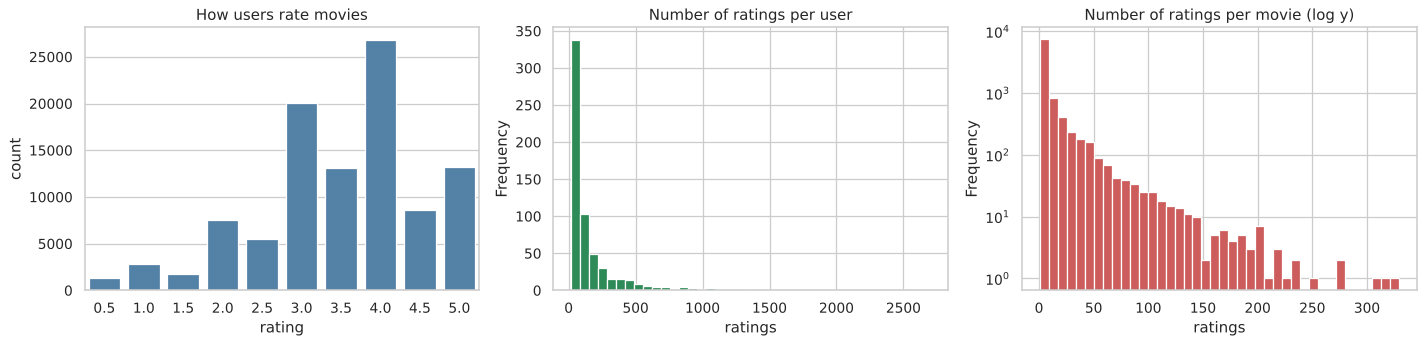

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))

sns.countplot(x="rating", data=ratings, color="steelblue", ax=ax[0])
ax[0].set_title("How users rate movies")

ratings.groupby("userId").size().plot(kind="hist", bins=40, ax=ax[1], color="seagreen")
ax[1].set_title("Number of ratings per user")
ax[1].set_xlabel("ratings")

ratings.groupby("movieId").size().plot(kind="hist", bins=40, ax=ax[2], color="indianred")
ax[2].set_yscale("log")  # log scale so the few very popular movies do not hide the rest
ax[2].set_title("Number of ratings per movie (log y)")
ax[2].set_xlabel("ratings")

plt.tight_layout()
plt.show()

**Implementation note**

Summary statistics are calculated for the charts, including the minimum, median and maximum number of ratings per user and per movie.

The analysis also counts movies with only one rating and movies with fewer than five ratings. These figures help identify movies with limited interaction history, for which collaborative-filtering similarity may be less reliable.

In [6]:
per_user = ratings.groupby("userId").size()
per_movie = ratings.groupby("movieId").size()
print("Ratings per user  -> min:", per_user.min(), "| median:", per_user.median(), "| max:", per_user.max())
print("Ratings per movie -> min:", per_movie.min(), "| median:", per_movie.median(), "| max:", per_movie.max())
# cold start movies are the ones with very few ratings
print("Movies with only 1 rating:", (per_movie == 1).sum())
print("Movies with fewer than 5 ratings:", (per_movie < 5).sum())

Ratings per user  -> min: 20 | median: 70.5 | max: 2698
Ratings per movie -> min: 1 | median: 3.0 | max: 329
Movies with only 1 rating: 3446
Movies with fewer than 5 ratings: 6074


### Findings

- **Ratings:** The average rating is approximately **3.5**, and 4.0 is the most common rating. Ratings therefore tend towards the higher end of the available scale.
- **Ratings per user:** Every user has rated at least 20 movies, although the number varies widely. Some users have submitted thousands of ratings.
- **Ratings per movie:** The median movie has only **3 ratings**, while the most-rated movie has 329. Many movies have very few ratings, while a smaller group receives substantially more attention.

This uneven pattern is known as a **long-tail distribution**: a relatively small number of popular movies receive many ratings, while a large number of movies receive relatively few.

### Why this matters

Collaborative filtering relies on user–movie interaction history to identify reliable patterns. Movies with very few ratings provide limited evidence for similarity calculations. Accordingly, movies with **at least five ratings in the training set** are included in the collaborative-filtering candidate set. Genre information provides an additional signal for movies outside this set.

### 2.3 Movie genres

Movie genres provide descriptive information about the catalogue and form the item features used by the content-based component.

**Implementation note**

The `genres` column can contain multiple labels separated by a vertical bar, such as `Comedy|Drama`.

The labels are split so that each genre can be counted separately, and the number of movies associated with each genre is plotted. Since a movie can belong to more than one genre, genre counts are not mutually exclusive.

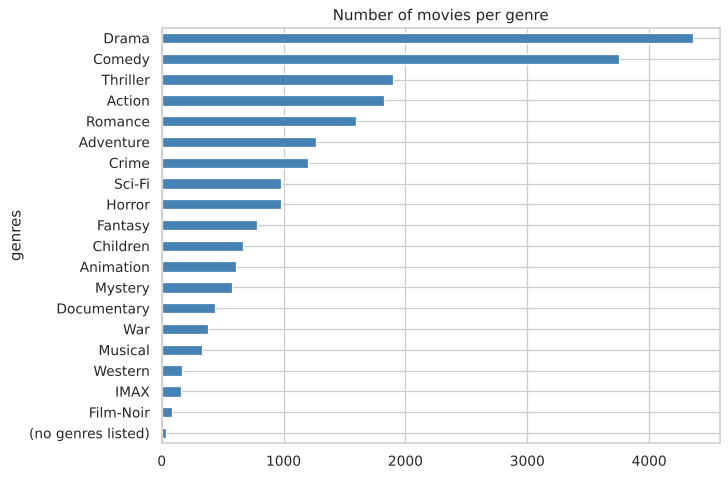

In [7]:
# split 'Comedy|Drama' into separate rows, then count
genre_counts = movies.genres.str.split("|").explode().value_counts()

plt.figure(figsize=(8, 6))
genre_counts.sort_values().plot(kind="barh", color="steelblue")
plt.title("Number of movies per genre")
plt.show()

### Findings

Drama and Comedy are among the most common genres in the catalogue.

Genre labels provide the content-based component with information about a movie even when that movie has few or no ratings. A small number of records have the label `no genres listed`; these records provide no useful genre detail.

**Why this matters:** Ratings describe how users respond to movies, while genres describe movie content. Combining both sources gives the hybrid model interaction-based and content-based information.

## 3. Data Preparation

Data preparation consists of five main steps:

1. **Train/test split:** 80% of the ratings are allocated to the training set, while 20% are held out for testing. The training set is used to fit the model; the test set is reserved for evaluation on ratings not used during fitting.
2. **Create user and movie indices:** Original IDs are mapped to row indices so that user–movie matrices can be constructed.
3. **Calculate a rating baseline:** A starting prediction is estimated using the global average, the user's rating tendency (*user bias*), and the movie's general rating tendency (*item bias*).
4. **Calculate residuals:** The baseline is subtracted from each training rating. A residual indicates whether the actual rating is above or below the baseline prediction.
5. **Prepare model features:** Movies with at least five training ratings are retained for collaborative filtering, and genres are converted into numerical TF-IDF features for content-based filtering.

### Understanding the baseline and residual

The baseline is:

`Baseline = global mean + user bias + item bias`

The residual is:

`Residual = actual rating − baseline`

**Example:** Suppose the global average is 3.5, a user tends to rate 0.5 stars above average, and a movie tends to score 0.3 stars above average. The baseline prediction is 4.3. If the actual rating is 5 stars, the residual is +0.7. This means the user rated the movie 0.7 stars higher than the baseline expected.

These values are calculated using the **training data only** to prevent information from the held-out test ratings leaking into model preparation.

**Implementation note**

The ratings are split into:

- **Training set (80%):** used to calculate biases, residuals and similarities.
- **Test set (20%):** held aside for model evaluation.

The `random_state=42` parameter makes the random split reproducible, so the same observations are assigned to each set when the notebook is rerun.

Each user ID and movie ID is also mapped to a numerical row index. These indices allow ratings to be stored and accessed in matrix form.

In [8]:
# 1. Train / test split
# random_state makes the split the same every time I run it
train, test = train_test_split(ratings, test_size=0.2, random_state=42)

user_ids = np.sort(ratings.userId.unique())
# dictionaries that turn ids into row numbers
uidx = {u: i for i, u in enumerate(user_ids)}              # userId  -> row number
midx = {m: i for i, m in enumerate(movies.movieId)}        # movieId -> row number in movies

train = train.assign(ui=train.userId.map(uidx), ii=train.movieId.map(midx))
test = test.assign(ui=test.userId.map(uidx), ii=test.movieId.map(midx)).reset_index(drop=True)
print("Train:", len(train), "| Test:", len(test))

Train: 80668 | Test: 20168


**Implementation note**

The baseline rating for each user–movie pair is calculated using training data:

`global mean + user bias + item bias`

- **Global mean (`mu`):** the average rating in the training set.
- **User bias:** the difference between a user's average rating and the global mean.
- **Item bias:** the movie's rating tendency after accounting for the global mean and the user's tendency.

The item bias is *shrunk* by adding 10 to the denominator. This pulls estimates for movies with very few ratings closer to zero because estimates based on small samples are less reliable.

Each training residual is then calculated as the actual rating minus the baseline prediction.

In [9]:
# 2. Baseline = global mean + user bias + item bias  (calculated from TRAIN only)
mu = train.rating.mean()

user_bias = train.groupby("ui").rating.mean().reindex(range(len(user_ids))).values - mu

# item bias is shrunk (+10 in the denominator) so movies with 1-2 ratings do not get extreme values
tmp = train.rating - mu - user_bias[train.ui]
stats = tmp.groupby(train.ii).agg(["sum", "count"])
item_bias = np.zeros(len(movies))
# shrinking: movies with few ratings get a smaller bias
item_bias[stats.index] = stats["sum"] / (stats["count"] + 10)

# 3. Residuals
# residual = what the user gave minus what I expected
train["res"] = train.rating - (mu + user_bias[train.ui] + item_bias[train.ii])

print("Global mean:", round(mu, 3))
print("Residual mean (should be close to 0):", round(train.res.mean(), 4))

Global mean: 3.503
Residual mean (should be close to 0): -0.033


**Implementation note**

For collaborative filtering, the candidate set includes movies with **at least five ratings in the training set**.

Movies below this threshold are excluded from the collaborative-filtering candidate set because there is insufficient rating evidence to estimate movie-to-movie similarity reliably.

The `pos` array maps each movie to its position in the smaller candidate list. A value of `-1` indicates that a movie is not a collaborative-filtering candidate; in this project, it is treated as a low-history or cold-start movie for the collaborative component.

In [10]:
# 4. Candidate movies for collaborative filtering: at least 5 ratings in train
counts = train.ii.value_counts()
# movies with enough ratings
cand = np.sort(counts[counts >= 5].index.values)       # row numbers in `movies`
# -1 means: not a candidate (cold movie)
pos = -np.ones(len(movies), dtype=int)                 # position inside the candidate list (-1 = not a candidate)
pos[cand] = np.arange(len(cand))

print("Candidate movies for CF:", len(cand), "out of", len(movies))
print("Test ratings that are on a non-candidate (cold) movie:", (pos[test.ii] < 0).sum())

Candidate movies for CF: 3219 out of 9742
Test ratings that are on a non-candidate (cold) movie: 2995


**Implementation note**

Each movie's genre labels are converted into numerical features using **TF-IDF**.

TF-IDF assigns numerical weights to genre terms based on how informative they are across the catalogue. The resulting feature vector represents each movie's genre profile. Movies with overlapping genre features can have higher cosine similarity.

Each row is normalised to unit length so that the dot product between two genre vectors is equivalent to cosine similarity.

In [11]:
# 5. Genre features (TF-IDF), one row per movie, scaled to length 1
tfidf = TfidfVectorizer(token_pattern=r"[^|]+", lowercase=False)
G = tfidf.fit_transform(movies.genres).toarray()
# scale each row to length 1 so cosine similarity is easy
G = G / np.linalg.norm(G, axis=1, keepdims=True).clip(1e-9)
print("Genre feature matrix:", G.shape)

Genre feature matrix: (9742, 20)


## 4. Modelling

The modelling stage includes baseline models, an item-based collaborative-filtering model, a genre-based content model, and a hybrid model that combines the two recommendation signals.

### 4.1 Baseline models

The baseline models provide simple points of comparison:

- **Global mean:** predicts the same average rating for every user and movie.
- **Bias baseline:** adjusts the global average for the user's rating tendency and the movie's general rating tendency.

The more advanced models are compared against these baseline predictions.

### 4.2 Item-based collaborative filtering

Item-based collaborative filtering identifies movies that users have rated in similar ways. It relies on rating behaviour rather than movie descriptions.

For each pair of movies, **residual rating patterns** are compared using cosine similarity. Residuals help focus the comparison on whether users rated a movie above or below its expected baseline, rather than simply reflecting generous users or generally popular movies.

To predict a user's rating for a target movie:

1. Identify movies the user has already rated.
2. Select up to the **30 most similar** rated movies.
3. Calculate a similarity-weighted average of the user's residuals for those neighbouring movies.
4. Add the estimated residual to the target movie's baseline.

Similarities are also shrunk according to the number of users who rated both movies. Similarity estimates based on very few shared users are less reliable and are therefore reduced.

### 4.3 Content-based filtering using genres

This method compares the genre features of a target movie with the genres of movies the user has rated. It uses TF-IDF genre vectors and cosine similarity.

Unlike collaborative filtering, content-based filtering does not require other users to have rated the target movie. It can therefore provide a signal for a movie with limited rating history, provided useful genre information is available.

### 4.4 Hybrid model

The hybrid model combines the collaborative and content-based residual predictions:

`Prediction = baseline + w × CF residual + (1 − w) × content residual`

Here, `w` controls the relative contribution of collaborative filtering. For example, `w = 0.7` assigns 70% weight to the collaborative residual and 30% to the genre-based residual for eligible movies.

For movies outside the collaborative-filtering candidate set, the content-based residual is used because collaborative similarity is unavailable.

**Key point:** The baseline accounts for general rating tendencies; collaborative filtering learns from rating patterns; content-based filtering learns from movie genres; and the hybrid model combines the two signals.

**Implementation note: item-to-item similarity matrix**

The item-to-item collaborative-filtering similarity matrix is constructed through the following steps:

- A user-by-movie matrix is created using training residuals.
- Cosine similarity is calculated between every pair of candidate movies.
- The number of users who rated each pair of movies in common is counted.
- Similarity values are shrunk when the number of shared raters is small.
- Each movie's similarity with itself is set to zero so that it cannot become its own neighbour.

The resulting matrix has **3,219 rows and 3,219 columns**: one row and one column for each movie that meets the five-training-ratings threshold.

A high positive value indicates similar residual rating patterns. It reflects similarity in user responses, not necessarily similarity in genre, storyline or other movie content.

In [12]:
# Collaborative filtering similarity between candidate movies
tc = train[train.ii.isin(cand)]
R = csr_matrix((tc.res.values, (tc.ui.values, pos[tc.ii.values])), shape=(len(user_ids), len(cand)))
B = csr_matrix((np.ones(len(tc)), (tc.ui.values, pos[tc.ii.values])), shape=R.shape)

dot = (R.T @ R).toarray()
norms = np.sqrt(np.diag(dot))
# cosine similarity: close to 1 = rated the same way by users
sim_cf = dot / np.outer(norms, norms).clip(1e-9)          # cosine similarity

n_common = (B.T @ B).toarray()                             # how many users rated both movies
sim_cf = sim_cf * n_common / (n_common + 10)               # shrink when few users in common
# a movie should not be its own neighbour
np.fill_diagonal(sim_cf, 0)
print("Similarity matrix:", sim_cf.shape)

Similarity matrix: (3219, 3219)


**Implementation note**

Each user's training history is organised so the prediction functions can quickly access:

- all movies rated by the user and their residuals, for content-based comparisons;
- the subset of those movies that are collaborative-filtering candidates and their residuals.

Two helper functions are then defined. `cf_residual()` estimates a residual using item-to-item rating similarity, while `content_residual()` estimates a residual using genre similarity.

Both functions use a weighted average of the user's residuals on similar movies. Up to 30 neighbours are considered, and a stabilising term is included in the denominator so that weak similarity evidence does not produce an excessively large prediction.

In [13]:
# What does the user already have? (rated items and their residuals)
user_all, user_cand = {}, {}
for u, g in train.groupby("ui"):
    user_all[u] = (g.ii.values, g.res.values)
    m = pos[g.ii.values] >= 0
    user_cand[u] = (pos[g.ii.values[m]], g.res.values[m])

# average of the user's residuals on the k most similar movies
def neighbour_average(S, r, k=30, lam=1.0):
    # S: similarity of target movies (rows) to the movies the user rated (columns)
    # r: the user's residuals on those rated movies
    if S.shape[1] > k:
        idx = np.argpartition(-S, k - 1, axis=1)[:, :k]
        Sk = np.take_along_axis(S, idx, 1)
        rk = r[idx]
    else:
        Sk, rk = S, np.broadcast_to(r, S.shape)
    # lam keeps weak evidence close to 0
    return (Sk * rk).sum(1) / (np.abs(Sk).sum(1) + lam)    # lam keeps weak evidence close to 0

def cf_residual(cand_pos, J_c, r_c):
    return neighbour_average(sim_cf[np.ix_(cand_pos, J_c)], r_c)

def content_residual(movie_rows, J_a, r_a):
    return neighbour_average(G[movie_rows] @ G[J_a].T, r_a)

**Implementation note**

For every rating in the held-out test set, the following estimates are calculated:

1. A baseline prediction.
2. A collaborative-filtering residual estimate, when the target movie is in the candidate set.
3. A content-based residual estimate using genre similarity.

The collaborative and content estimates are stored separately to support comparison of each approach and testing of different hybrid weights during evaluation.

The user histories used for these estimates come from the training set, not from the test ratings being predicted.

In [14]:
# Predict every test rating with each component
base_pred = mu + user_bias[test.ui] + item_bias[test.ii]
in_cand = (pos[test.ii] >= 0)
cf_res = np.zeros(len(test))
content_res = np.zeros(len(test))

for u, g in test.groupby("ui"):
    ix = g.index.values
    J_a, r_a = user_all[u]
    J_c, r_c = user_cand[u]
    content_res[ix] = content_residual(g.ii.values, J_a, r_a)
    m = in_cand[ix]
    if m.any():
        cf_res[ix[m]] = cf_residual(pos[g.ii.values[m]], J_c, r_c)

# w = how much I trust CF; cold movies use genres only
def hybrid(w):
    return base_pred + np.where(in_cand, w * cf_res + (1 - w) * content_res, content_res)
print("Done. Predictions made for", len(test), "test ratings")

Done. Predictions made for 20168 test ratings


## 5. Evaluation

The models are evaluated on the **20% test set** held back during data preparation.

Two types of evaluation are used because accurate rating prediction and useful ranked recommendations are related but distinct tasks.

**Implementation note**

Two rating-prediction error metrics are calculated for each model:

- **RMSE (Root Mean Squared Error):** squares each prediction error, calculates the mean squared error, and takes the square root. Larger errors receive greater penalty.
- **MAE (Mean Absolute Error):** calculates the average absolute difference between predicted and actual ratings. It is measured in stars and is straightforward to interpret.

Predicted ratings are clipped to the dataset's allowed range of 0.5 to 5 stars before the errors are calculated.

For both metrics, **lower is better**.

In [15]:
# predictions are kept between 0.5 and 5 stars
def rmse(p): return np.sqrt(np.mean((np.clip(p, 0.5, 5) - test.rating) ** 2))
def mae(p):  return np.mean(np.abs(np.clip(p, 0.5, 5) - test.rating))

models = {
    "Global mean": np.full(len(test), mu),
    "Bias baseline": base_pred,
    "Item-based CF": base_pred + cf_res,
    "Content-based (genres)": base_pred + content_res,
    "Hybrid (w=0.5)": hybrid(0.5),
    "Hybrid (w=0.7)": hybrid(0.7),
    "Hybrid (w=0.9)": hybrid(0.9),
}
results = pd.DataFrame({n: {"RMSE": rmse(p), "MAE": mae(p)} for n, p in models.items()}).T.round(4)
results

,RMSE,MAE
Global mean,1.0488,0.8316
Bias baseline,0.8932,0.6810
Item-based CF,0.8573,0.6499
Content-based (genres),0.8600,0.6572
Hybrid (w=0.5),0.8476,0.6457
Hybrid (w=0.7),0.8467,0.6441
Hybrid (w=0.9),0.8480,0.6444


**Implementation note**

The RMSE values from the comparison table are plotted to show which model has the smallest prediction error.

A shorter bar represents a lower RMSE and therefore better rating-prediction performance on the test set.

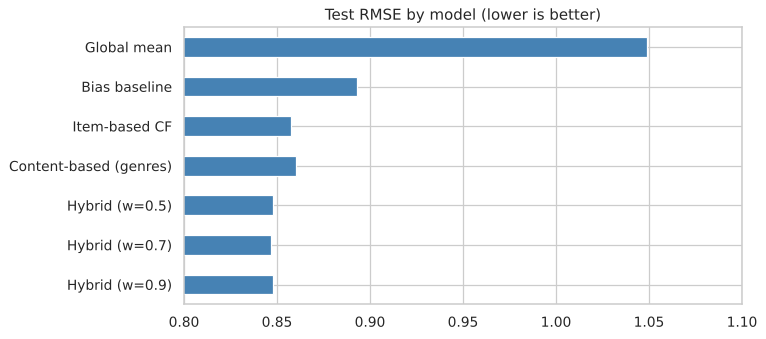

In [16]:
results["RMSE"].plot(kind="barh", color="steelblue", figsize=(8, 4))
plt.xlim(0.8, 1.1)
plt.title("Test RMSE by model (lower is better)")
plt.gca().invert_yaxis()
plt.show()

### Rating-prediction results and interpretation

The test results show:

- **Global mean:** RMSE 1.0488, MAE 0.8316.
- **Bias baseline:** RMSE 0.8932, MAE 0.6810. This is a substantial improvement over the global mean, showing that user and movie rating tendencies matter.
- **Item-based CF:** RMSE 0.8573, MAE 0.6499. Similarity between movies adds useful information.
- **Content-based genres:** RMSE 0.8600, MAE 0.6572.
- **Hybrid with `w = 0.7`:** RMSE 0.8467, MAE 0.6441, the lowest errors among the models compared.

The hybrid model with `w = 0.7` performs best on these rating-prediction metrics. This indicates that combining rating-based and genre-based signals predicts held-out star ratings slightly more accurately than either component alone.

### Methodological note

The values `w = 0.5`, `0.7` and `0.9` were compared, and the best result was selected using the test-set scores. A stricter evaluation would use a separate validation set to select the weight and reserve the test set for one final assessment. Since the test set informed parameter selection, the reported performance may be somewhat optimistic.

### 5.2 Cold-start movie check

This section focuses on test ratings for movies that did **not** reach the five-rating threshold in the training set.

For these movies, the collaborative-filtering component has no usable item-similarity representation in the candidate matrix. The analysis therefore examines whether the genre-based content signal improves prediction compared with the bias baseline.

**Implementation note**

The test ratings for movies outside the collaborative-filtering candidate set are identified.

The RMSE is then compared for:

- the bias baseline alone; and
- the hybrid prediction, which uses the content-based residual for these low-history movies.

This comparison isolates the subset where the collaborative-filtering component cannot contribute.

In [17]:
# cold = not a candidate movie
cold = ~in_cand
print("Cold start test ratings:", cold.sum())

def rmse_sub(p, mask): return np.sqrt(np.mean((np.clip(p, 0.5, 5)[mask] - test.rating[mask]) ** 2))

pd.DataFrame({
    "Bias baseline": {"RMSE on cold movies": rmse_sub(base_pred, cold)},
    "Hybrid (content for cold movies)": {"RMSE on cold movies": rmse_sub(hybrid(0.7), cold)},
}).T.round(4)

Cold start test ratings: 2995


,RMSE on cold movies
Bias baseline,0.9909
Hybrid (content for cold movies),0.9451


### Cold-start result and interpretation

There are **2,995 test ratings** for movies outside the collaborative-filtering candidate set.

- Bias-baseline RMSE: **0.9909**
- Hybrid prediction using genre information: **0.9451**

The lower RMSE indicates that genre similarity improves rating prediction for this subset compared with the bias baseline alone.

The improvement is useful, but genres provide only a limited description of a movie. They do not capture every reason someone may like a film, such as its plot, actors, director or tone.

**Important distinction:** This evaluation concerns *cold-start movies* (movies with insufficient rating history), not entirely new users. A new-user scenario is tested separately in the deployment examples.

### 5.3 Top-five recommendations: Precision@5

RMSE and MAE measure rating-prediction accuracy. They do not directly measure whether the **five highest-ranked movies in a recommendation list** are relevant. Ranking performance is therefore evaluated separately.

For each evaluated user:
1. The training ratings are treated as the user's known history.
2. Movies already rated in the training set are excluded.
3. The remaining candidate movies are scored and the top five are selected.
4. Each recommendation is checked against the user's held-out test ratings. A test rating of **4 or higher** counts as relevant.

A recommended movie meeting this threshold is counted as a **hit**. The evaluation includes **596 users**: users with at least one positively rated test movie within the candidate set.

- **Precision@5** = total hits across users ÷ (5 × number of evaluated users). It represents the average proportion of the five recommendations that were relevant.
- **Hit rate** = proportion of evaluated users who received at least one hit in their top-five list.

The models are compared with simple alternatives: random recommendations, most-rated movies, and top-rated movies based on item bias.

**Implementation note**

For each user, a top-five list is generated for each recommendation approach. The number of recommended movies that overlap with the user's positively rated test movies (ratings of 4 or higher) is then counted.

Popularity boosts of 0.1, 0.2 and 0.3 are also tested. These add an additional score to movies with more training ratings.

The purpose is to assess whether combining personal relevance with general popularity improves the top-five ranking.

In [18]:
rng = np.random.default_rng(42)
# movies the user rated 4+ in the test set = "liked"
test_liked = test[(test.rating >= 4) & (pos[test.ii] >= 0)]
liked_by_user = test_liked.groupby("ui").ii.apply(lambda s: set(pos[s.values]))

popularity = counts.reindex(cand).values               # how many train ratings
log_pop = np.log(popularity)                            # popularity on a log scale
top_rated = item_bias[cand]
cand_rows = cand                                        # row numbers in `movies`

# pick the 5 highest scores, ignoring movies already seen
def top5(scores, seen):
    s = scores.copy()
    s[seen] = -np.inf
    idx = np.argpartition(-s, 5)[:5]
    return set(idx)

betas = [0.1, 0.2, 0.3]                                 # how much extra weight popularity gets
names = ["Random", "Most rated", "Top rated", "Item-based CF", "Content-based", "Hybrid (w=0.7)"]         + [f"Hybrid + popularity ({b})" for b in betas]
hits = {m: [] for m in names}
# loop over each user and build their lists
for u, liked in liked_by_user.items():
    J_a, r_a = user_all[u]
    J_c, r_c = user_cand[u]
    seen = J_c
    cf_s = top_rated + cf_residual(np.arange(len(cand)), J_c, r_c)
    ct_s = top_rated + content_residual(cand_rows, J_a, r_a)
    cf_part = cf_residual(np.arange(len(cand)), J_c, r_c)
    ct_part = content_residual(cand_rows, J_a, r_a)
    hy_s = top_rated + 0.7 * cf_part + 0.3 * ct_part
    lists = {
        "Random": top5(rng.random(len(cand)), seen),
        "Most rated": top5(popularity.astype(float), seen),
        "Top rated": top5(top_rated, seen),
        "Item-based CF": top5(cf_s, seen),
        "Content-based": top5(ct_s, seen),
        "Hybrid (w=0.7)": top5(hy_s, seen),
    }
    for b in betas:
        lists[f"Hybrid + popularity ({b})"] = top5(hy_s + b * log_pop, seen)
    for name, rec in lists.items():
        hits[name].append(len(rec & liked))

rank_results = pd.DataFrame({
    n: {"Precision@5": np.mean(h) / 5, "Hit rate": np.mean(np.array(h) > 0)} for n, h in hits.items()
}).T.round(4)
print("Users evaluated:", len(liked_by_user))
rank_results

Users evaluated: 596


,Precision@5,Hit rate
Random,0.0057,0.0252
Most rated,0.1493,0.4597
Top rated,0.0557,0.2097
Item-based CF,0.0782,0.2869
Content-based,0.0497,0.2013
Hybrid (w=0.7),0.0775,0.2919
Hybrid + popularity (0.1),0.1315,0.4178
Hybrid + popularity (0.2),0.1490,0.4446
Hybrid + popularity (0.3),0.1607,0.4614


**Implementation note**

Precision@5 is plotted for each recommendation list.

Higher bars indicate that a larger proportion of the five recommended movies were rated 4 or higher by the evaluated users in the test set.

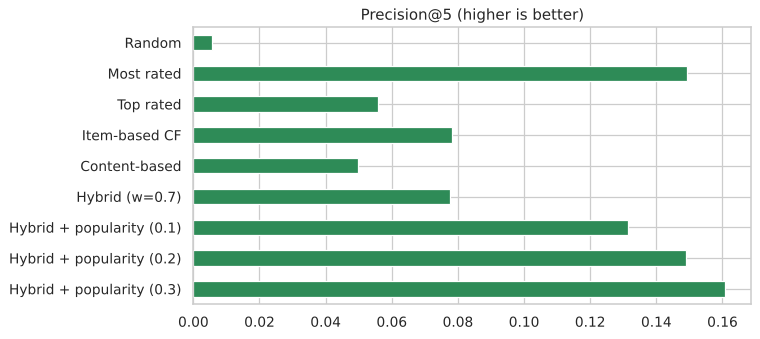

In [19]:
rank_results["Precision@5"].plot(kind="barh", color="seagreen", figsize=(8, 4))
plt.title("Precision@5 (higher is better)")
plt.gca().invert_yaxis()
plt.show()

### Precision@5 results and interpretation

The results show an important difference between rating prediction and top-five ranking:

- Random recommendations perform very poorly: Precision@5 = **0.0057**.
- The most-rated list achieves **0.1493**.
- Item-based CF achieves **0.0782**.
- The plain hybrid (`w = 0.7`) achieves **0.0775**.
- The hybrid with a popularity boost of 0.3 achieves the highest Precision@5 in this comparison: **0.1607**.

The plain hybrid does **not** outperform the most-rated baseline on Precision@5. Popular movies are more likely to appear in users' test ratings, so popularity can perform strongly in this offline evaluation.

Adding a popularity boost improves the hybrid's ranking. With a weight of 0.3, the hybrid plus popularity performs better than the most-rated baseline in this test. The trade-off is that stronger popularity weighting can make recommendations more mainstream and less personalised.

A popularity weight of **0.3** is used in the recommendation function because it produced the strongest Precision@5 among the values tested.

### Interpreting this metric carefully

A recommendation is counted as a hit only if the user rated that movie in the test set and gave it at least 4 stars. A movie the user might have enjoyed but never rated is not counted as a hit. Precision@5 is therefore an offline estimate based on available test ratings, not a direct measure of real-world satisfaction.

This evaluation also ranks only candidate movies that meet the collaborative-filtering threshold. It does not measure the recommendation quality of low-rating-history movies excluded from that candidate set.

## 6. Deployment: using the recommendation function

A Python function called `recommend()` demonstrates how the model could be used by an application.

The input is a dictionary containing movie titles and the user's ratings. The output is a table of five recommended movies, their genres and predicted ratings.

### What happens inside the function

1. **Identify the movies:** match the supplied titles to rows in the movie catalogue.
2. **Estimate the new user's rating tendency:** calculate a user-bias estimate from the supplied ratings and the existing movie biases.
3. **Calculate residuals:** determine how far the user's ratings are above or below the expected baseline.
4. **Score candidate movies:** use genre similarity and, when enough ratings are supplied, collaborative filtering as well.
5. **Apply popularity and remove seen movies:** add the configured popularity boost and exclude movies already rated by the user.
6. **Return the top five:** sort by the final ranking score and return the five highest-scoring candidates.

### New-user cold-start rule in this implementation

If the user supplies fewer than **five ratings**, or fewer than three of those rated movies are collaborative-filtering candidates, the function switches to **content-based recommendations only** and turns off the popularity boost.

This is a practical fallback because a very short user history is not sufficient for reliable collaborative filtering.

**Note:** The list is sorted by a ranking score that includes the popularity boost. The displayed `predicted_rating` is calculated separately, so the rows are not guaranteed to be in descending predicted-rating order.

**Implementation note**

A title-lookup helper and the main `recommend()` function are defined.

`find_movie()` locates the exact movie title used in the dataset. `recommend()` accepts the user's title-to-rating dictionary, selects the appropriate recommendation mode, excludes movies already rated by the user, and returns the top five candidates.

In [20]:
title_to_row = {t: i for i, t in enumerate(movies.title)}

def find_movie(text):
    """Helper: search for the exact title the system uses."""
    return movies[movies.title.str.contains(text, case=False, regex=False)][["title", "genres"]]

# main function: ratings in, top 5 out
def recommend(my_ratings, n=5, w=0.7, pop_weight=0.3):
    rows = np.array([title_to_row[t] for t in my_ratings])
    r = np.array(list(my_ratings.values()), dtype=float)

    # this user's bias and residuals
    # how generous is this user?
    ub_new = np.mean(r - mu - item_bias[rows]) * len(r) / (len(r) + 5)
    res = r - (mu + ub_new + item_bias[rows])

    # score every candidate movie
    ct_part = content_residual(cand, rows, res)
    in_c = pos[rows] >= 0
    # enough ratings -> use CF; otherwise cold start
    if len(my_ratings) >= 5 and in_c.sum() >= 3:
        cf_part = cf_residual(np.arange(len(cand)), pos[rows[in_c]], res[in_c])
        score = item_bias[cand] + w * cf_part + (1 - w) * ct_part
        mode = "hybrid + popularity boost"
    else:
        score = item_bias[cand] + ct_part
        pop_weight = 0                                    # with so few ratings, stay close to the user's genres
        mode = "content-based only (cold start user)"

    ranking_score = score + pop_weight * log_pop         # small boost for popular movies
    ranking_score[np.isin(cand, rows)] = -np.inf         # do not recommend what they rated
    best = np.argsort(-ranking_score)[:n]
    out = movies.iloc[cand[best]][["title", "genres"]].copy()
    out["predicted_rating"] = np.clip(mu + ub_new + score[best], 0.5, 5).round(2)
    print("Mode used:", mode)
    return out.reset_index(drop=True)

find_movie("Matrix, The")

,title,genres
1939,"Matrix, The (1999)",Action|Sci-Fi|Thriller
5669,"Animatrix, The (2003)",Action|Animation|Drama|Sci-Fi


### 6.1 Example 1: science-fiction and action preferences

The function is tested with a fictional user profile containing high ratings for science-fiction and action films and lower ratings for romance films. This example checks whether the recommendations broadly reflect the supplied preferences.

**Implementation note**

A sample rating profile is created with high scores for movies such as *The Matrix*, *Terminator 2*, *Star Wars*, *Alien* and *Blade Runner*, and lower scores for *Titanic* and *Notting Hill*.

The profile is passed to `recommend()` and the five returned movies are inspected.

In [21]:
sci_fi_fan = {
    "Matrix, The (1999)": 5.0,
    "Terminator 2: Judgment Day (1991)": 4.5,
    "Star Wars: Episode IV - A New Hope (1977)": 5.0,
    "Alien (1979)": 4.5,
    "Blade Runner (1982)": 4.0,
    "Titanic (1997)": 2.0,
    "Notting Hill (1999)": 2.0,
}
recommend(sci_fi_fan)

Mode used: hybrid + popularity boost


,title,genres,predicted_rating
0,Raiders of the Lost Ark (Indiana Jones and the Raiders of the Lost Ark) (1981),Action|Adventure,4.45
1,Star Wars: Episode V - The Empire Strikes Back (1980),Action|Adventure|Sci-Fi,4.42
2,Fight Club (1999),Action|Crime|Drama|Thriller,4.36
3,Star Wars: Episode VI - Return of the Jedi (1983),Action|Adventure|Sci-Fi,4.38
4,"Shawshank Redemption, The (1994)",Crime|Drama,4.23


### Interpreting the recommendations

Four of the five recommendations are action or science-fiction adventures, broadly matching the high-rated movies in the sample profile.

*The Shawshank Redemption* is less obviously connected to those genres. One reason it may appear is the popularity boost: the ranking score includes both personal relevance and popularity.

This is a qualitative demonstration using an invented user profile. It is not evidence that a real user would necessarily like these movies.

### 6.2 Example 2: family and animation preferences

A second fictional user profile is tested to represent different preferences. The profile contains high ratings for family and animation movies and lower ratings for selected action or crime movies.

The purpose is to check whether changing the input ratings changes the recommendations.

**Implementation note**

A second sample rating dictionary is created, favouring movies such as *Toy Story*, *Finding Nemo*, *Shrek*, *The Lion King* and *Monsters, Inc.*

The ratings are passed to the same `recommend()` function. The model and its parameters remain unchanged; only the supplied user preferences differ.

In [22]:
family_fan = {
    "Toy Story (1995)": 5.0,
    "Finding Nemo (2003)": 5.0,
    "Shrek (2001)": 4.5,
    "Lion King, The (1994)": 5.0,
    "Monsters, Inc. (2001)": 4.5,
    "Matrix, The (1999)": 2.0,
    "Pulp Fiction (1994)": 2.0,
}
recommend(family_fan)

Mode used: hybrid + popularity boost


,title,genres,predicted_rating
0,Forrest Gump (1994),Comedy|Drama|Romance|War,4.18
1,Aladdin (1992),Adventure|Animation|Children|Comedy|Musical,4.31
2,"Princess Bride, The (1987)",Action|Adventure|Comedy|Fantasy|Romance,4.37
3,"Shawshank Redemption, The (1994)",Crime|Drama,4.11
4,Raiders of the Lost Ark (Indiana Jones and the Raiders of the Lost Ark) (1981),Action|Adventure,4.11


### 6.3 Example 3: new-user cold start with two ratings

This example demonstrates the **new-user cold-start fallback**.

The fictional new user has supplied only two movie ratings. Since this history is too short to meet the collaborative-filtering rule in the function, the system uses genre-based content recommendations only.

**Implementation note**

Two ratings are provided for a fictional new user: *Toy Story* receives 5 stars and *The Lion King* receives 4.5 stars.

The `recommend()` function is called to confirm that the content-based-only cold-start mode is selected.

In [23]:
new_user = {"Toy Story (1995)": 5.0, "Lion King, The (1994)": 4.5}
recommend(new_user)

Mode used: content-based only (cold start user)


,title,genres,predicted_rating
0,"Grand Day Out with Wallace and Gromit, A (1989)",Adventure|Animation|Children|Comedy|Sci-Fi,4.73
1,"Princess Bride, The (1987)",Action|Adventure|Comedy|Fantasy|Romance,4.70
2,Toy Story 3 (2010),Adventure|Animation|Children|Comedy|Fantasy|IMAX,4.70
3,Spirited Away (Sen to Chihiro no kamikakushi) (2001),Adventure|Animation|Fantasy,4.67
4,Monty Python and the Holy Grail (1975),Adventure|Comedy|Fantasy,4.64


### Interpreting the cold-start recommendations

The function reports that it is using **content-based only (cold start user)**. The recommendations include family-friendly, animation and comedy-style movies, broadly matching the two highly rated films.

Some recommendations may still be broader than the user's apparent taste because genre labels are limited and the candidate list is restricted to movies with at least five training ratings. In this new-user cold-start path, the popularity boost is turned off, so ranking relies on item bias and genre-based similarity.

This example demonstrates how the system can generate initial recommendations from a small amount of user information. As more ratings become available, the function can switch to the hybrid approach.

## 7. Conclusion and next steps

### Project summary

The CRISP-DM process is used to develop an offline movie recommendation prototype. The final system combines **item-based collaborative filtering** with **genre-based content filtering** and provides a `recommend()` function that returns five movies based on a user's ratings.

### Main findings

- The **bias baseline** performs better than predicting the global average for every user–movie pair. User and item rating tendencies provide useful information.
- **Item-based collaborative filtering** improves on the bias baseline by using similarities between movies.
- The **hybrid model with `w = 0.7`** achieves the lowest RMSE and MAE among the rating-prediction models tested.
- For the top-five ranking task, the plain hybrid is weaker than the most-rated baseline. Adding a **0.3 popularity boost** produces the highest Precision@5 among the tested lists (**0.1607**).
- Genre features improve rating prediction for movies with fewer than five training ratings, compared with the bias baseline.

### Limitations

1. **Limited genre information:** genres do not capture all the reasons a person may like a movie.
2. **Candidate restriction:** movies with fewer than five training ratings are not included in the top-five candidate list. The content-based method helps predict ratings for these movies in the cold-start analysis, but the deployment recommendation list remains restricted to the collaborative-filtering candidate set.
3. **Parameter selection:** the hybrid weight and popularity boost were selected by comparing results on the test set. A separate validation set would provide a more rigorous evaluation.
4. **Offline evaluation:** test ratings are only a proxy for user interest. A live A/B test would be needed to determine whether users actually engage with or enjoy the recommendations.
5. **New-user cold start:** the fallback uses genre similarity, but it still requires the user to provide at least some ratings.

### Next steps

- Use a separate validation set for selecting model parameters.
- Test matrix factorisation, such as SVD, and compare it with item-based collaborative filtering.
- Add richer movie information, such as tags, plot descriptions, actors or directors.
- Evaluate the model on a broader dataset and, if possible, conduct a real-user experiment.

### Presentation conclusion

The project demonstrates how a recommendation system can combine user-rating patterns with information about movie characteristics. The hybrid model achieves the strongest rating-prediction results, while a popularity boost improves the top-five ranking metric. The analysis also highlights the challenges of sparse data and cold start, and demonstrates how genre information can provide a useful fallback when rating history is limited.